# Train a quantum teacher, then deploy a classical feature surrogate

Follow Kipu’s public offline feature-distillation protocol using a small native reference teacher. This does not reproduce Kipu’s proprietary DQFE teacher or industrial results. Faithful imitation and useful task accuracy are separate measurements.

## 1. Set up

Expected runtime is measured in the execution report, not guaranteed for every machine. The examples run locally on simulators; no QPU account is needed.

In [1]:
import importlib.util, os, subprocess, sys
# Locally: clone this repository, create a Python 3.12 environment, and install
# pip install -e ".[qiskit,learning,notebooks]"
# In Colab: set the public GitHub URL here once the repository is published.
REPO_URL = os.environ.get("QML_TRICKS_REPO_URL", "")
if importlib.util.find_spec("qml_tricks") is None:
    if not REPO_URL:
        raise RuntimeError("Set REPO_URL to the public GitHub repository, or install this checkout first.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", f"qml-bag-of-tricks[qiskit,learning,notebooks] @ git+{REPO_URL}"])
FRAMEWORK = "qiskit"  # switch to pennylane or cirq after installing its extra
import json, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from qml_tricks.learning.models import QMLModel
ARTIFACTS = Path("results/local/notebooks")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0], "Framework:", FRAMEWORK)


Python: 3.12.3 Framework: qiskit


## 2. Train and freeze the teacher first

Use independent training, validation and test inputs. Labels define a bounded synthetic classification task. Only the first 100 training rows fit the native teacher; the larger training acquisition set teaches the student.

In [2]:
from qml_tricks.learning.offline_surrogate import OfflineFeatureSurrogate, ClassicalFeatureStudent
rng = np.random.default_rng(7)
X = rng.uniform(-1, 1, (512,2)); y = (np.sum(X**2, axis=1) > .7).astype(int)
teacher = QMLModel("reuploading", framework=FRAMEWORK, seed=7, steps=3).fit(X[:100],y[:100])
frozen_parameters = teacher.theta_.copy()
distiller = OfflineFeatureSurrogate(alpha=1e-6, student_kind="rbf_ridge")
distiller.fit_teacher(teacher, X[:384], y[:384], X[384:448], y[384:448])
assert np.array_equal(teacher.theta_, frozen_parameters)
print(json.dumps(distiller.validation_, indent=2))


{
  "feature_rmse": 0.007728307695889754,
  "relative_feature_rmse": 0.010278640524494306,
  "feature_r2": 0.9998943231000623,
  "acceptance_thresholds": {
    "min_agreement": 0.95,
    "max_accuracy_drop": 0.02,
    "max_relative_feature_rmse": 0.2
  },
  "confidence_statement": "held-out empirical validation, no universal accuracy guarantee",
  "teacher_student_agreement": 1.0,
  "teacher_accuracy": 0.671875,
  "student_accuracy": 0.671875,
  "accuracy_drop": 0.0,
  "passed": true
}


## 3. Audit the untouched test inputs

Both feature fidelity and teacher/student task accuracy are printed. High agreement can faithfully reproduce a weak teacher. The validation gate is an empirical criterion, not a guaranteed confidence bound. The RBF-ridge student is a local extension; Ridge is the family reported in Kipu’s public example.

{
  "feature_rmse": 0.007121748121865559,
  "relative_feature_rmse": 0.0096266932997358,
  "feature_r2": 0.9999072268467859,
  "acceptance_thresholds": {
    "min_agreement": 0.95,
    "max_accuracy_drop": 0.02,
    "max_relative_feature_rmse": 0.2
  },
  "confidence_statement": "held-out empirical validation, no universal accuracy guarantee",
  "teacher_student_agreement": 1.0,
  "teacher_accuracy": 0.578125,
  "student_accuracy": 0.578125,
  "accuracy_drop": 0.0,
  "passed": true
}


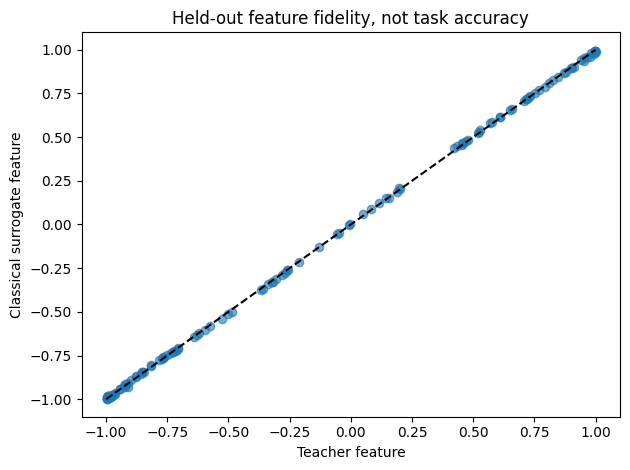

In [3]:
Q_test = distiller.teacher_.quantum_features(X[448:])
audit = distiller.audit_pairs(X[448:], Q_test, y[448:])
print(json.dumps(audit, indent=2))
predicted_features = distiller.surrogate_.predict(X[448:])
plt.scatter(Q_test.ravel(), predicted_features.ravel(), alpha=.6)
plt.plot([-1,1],[-1,1],"k--"); plt.xlabel("Teacher feature"); plt.ylabel("Classical surrogate feature")
plt.title("Held-out feature fidelity, not task accuracy"); plt.tight_layout(); plt.show()


## 4. Export only if the gate passes

The exported student has no teacher reference. For real Kipu measurements, use `fit_from_pairs(X_train, Q_train, y_train, X_validation, Q_validation, y_validation)`. No density matrix or quantum device is needed for student inference.

In [4]:
path = ARTIFACTS / "classical_student.joblib"
distiller.export_student(path)
student = ClassicalFeatureStudent.load(path)
assert not hasattr(student, "teacher_")
before = distiller.teacher_.resources_["state_preparations"]
predictions = student.predict(X[448:])
assert distiller.teacher_.resources_["state_preparations"] == before
assert np.array_equal(predictions, distiller.student().predict(X[448:]))
(ARTIFACTS / "surrogate.json").write_text(json.dumps(audit, indent=2))
print("Classical-only artifact:", path, "Test predictions:", len(predictions))


Classical-only artifact: results\local\notebooks\classical_student.joblib Test predictions: 64
